In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

### Get the data

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 4,5\zone 2\D2'
dir_name = r'16-Oct-2026_PaP_Pp10uW_ldap410nm_ldas680nm'


dir_name += '_treated'
filename = 'Trace'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


Make TF

In [3]:
height = 0.05e-5
threshold = 300e-7
ylim = 300e-7
Trace.tf_with_thermic = Trace.study_tf(Trace.DTT, Trace.delay, Trace.dt, height=height, threshold = threshold )

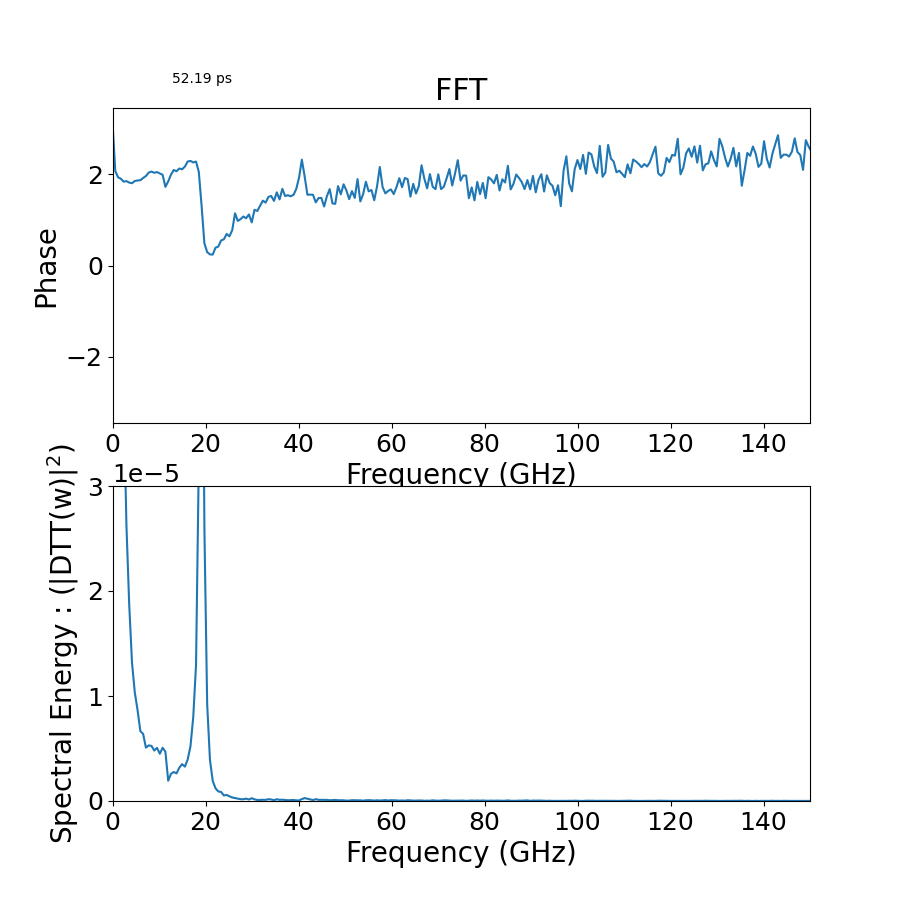

In [4]:
fig_raw_tf, ax_raw_tf = plt.subplots(nrows=2, figsize = (9, 9))

plot_tf_phase(Trace.tf_with_thermic, ax_raw_tf[0], ylim=ylim, xlim=(0, 150))
plot_tf_module(Trace.tf_with_thermic, ax_raw_tf[1], ylim=ylim, xlim=(0, 150))


#plt.tight_layout()
plt.show()

## Begin Thermal interpolation

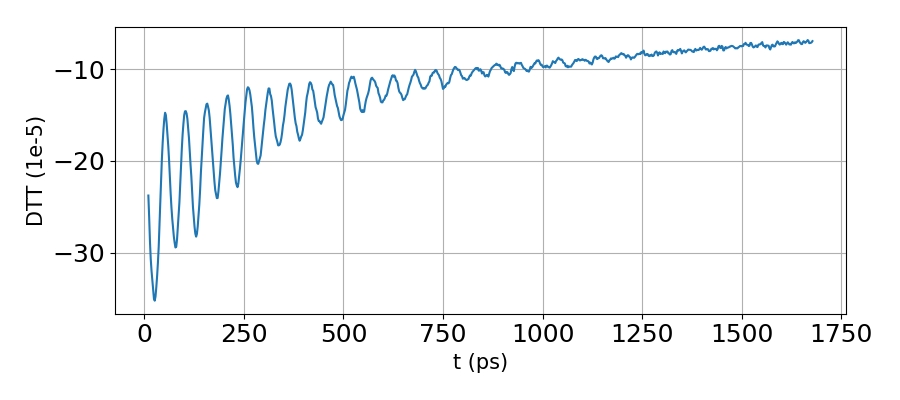

In [5]:
fig, ax = plt.subplots(figsize = (9,4))

Plot_delay(Trace, ax)
plt.tight_layout()

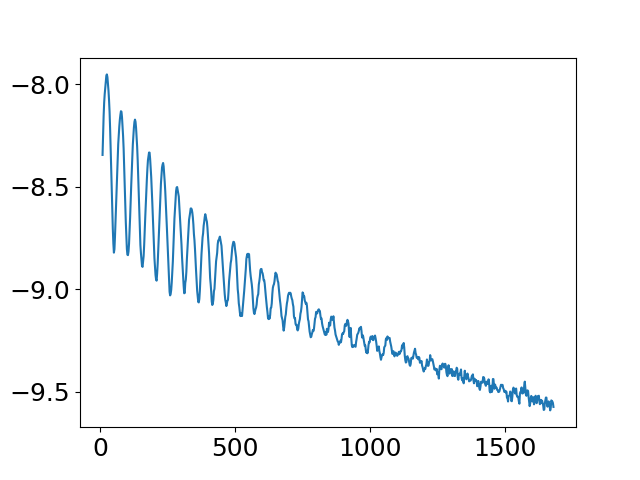

In [6]:
fig = plt.figure()

plt.plot(Trace.delay, np.log(-Trace.DTT))

### Create initial guesses and bounds

In [7]:
# Set the signal we're gonna fit
signe_pic = -1


#p0 = A1, tau1, A2, tau2, A3, tau3, A4, tau4. (times in ps)
p0 = signe_pic*7e-5, 2000., signe_pic*5e-5, 150., signe_pic*10.e-5, 8000., signe_pic*1e-5, 3200.


if signe_pic == -1 :
    Bounds_low =  [-np.inf, 0, -np.inf, 50, -np.inf, 400, -np.inf, 1500]
    Bounds_high = [0,np.inf,0,np.inf,0,np.inf, 0, np.inf]

else :
    Bounds_low =  [0, 4, 0, 100, 0, 400, 0, 1500]
    Bounds_high = [np.inf,np.inf,np.inf,np.inf,np.inf,np.inf, np.inf, np.inf]

In [8]:
Trace.fit_thermal_signal(p0, Bounds_high, Bounds_low)

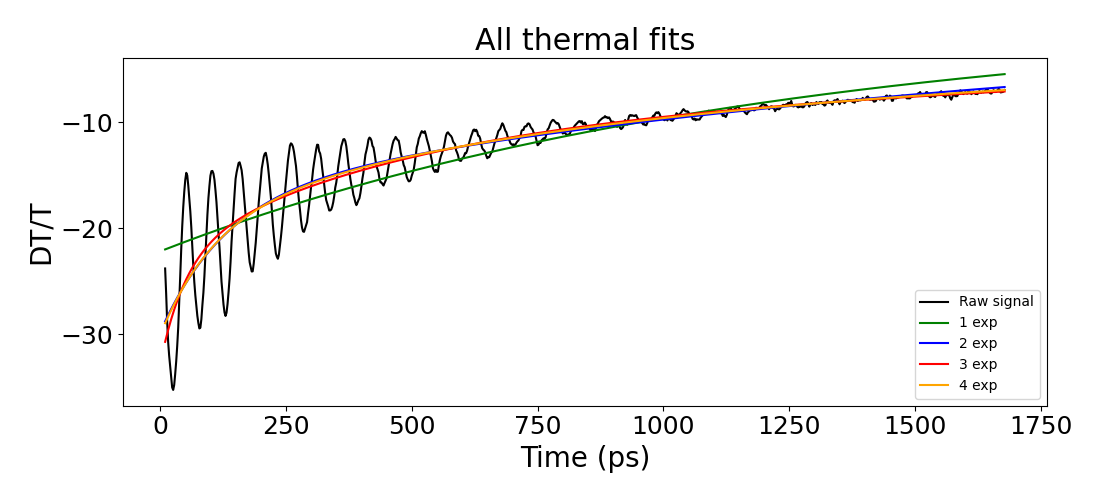

In [9]:
fig, ax = plt.subplots(figsize = (11,5))

Plot_multiple_thermal_fit(Trace,ax, n_min=1, n_max=4)
plt.tight_layout()
#save_in_dir(ftot, dir_save_treated_data, 'Thermal fits')

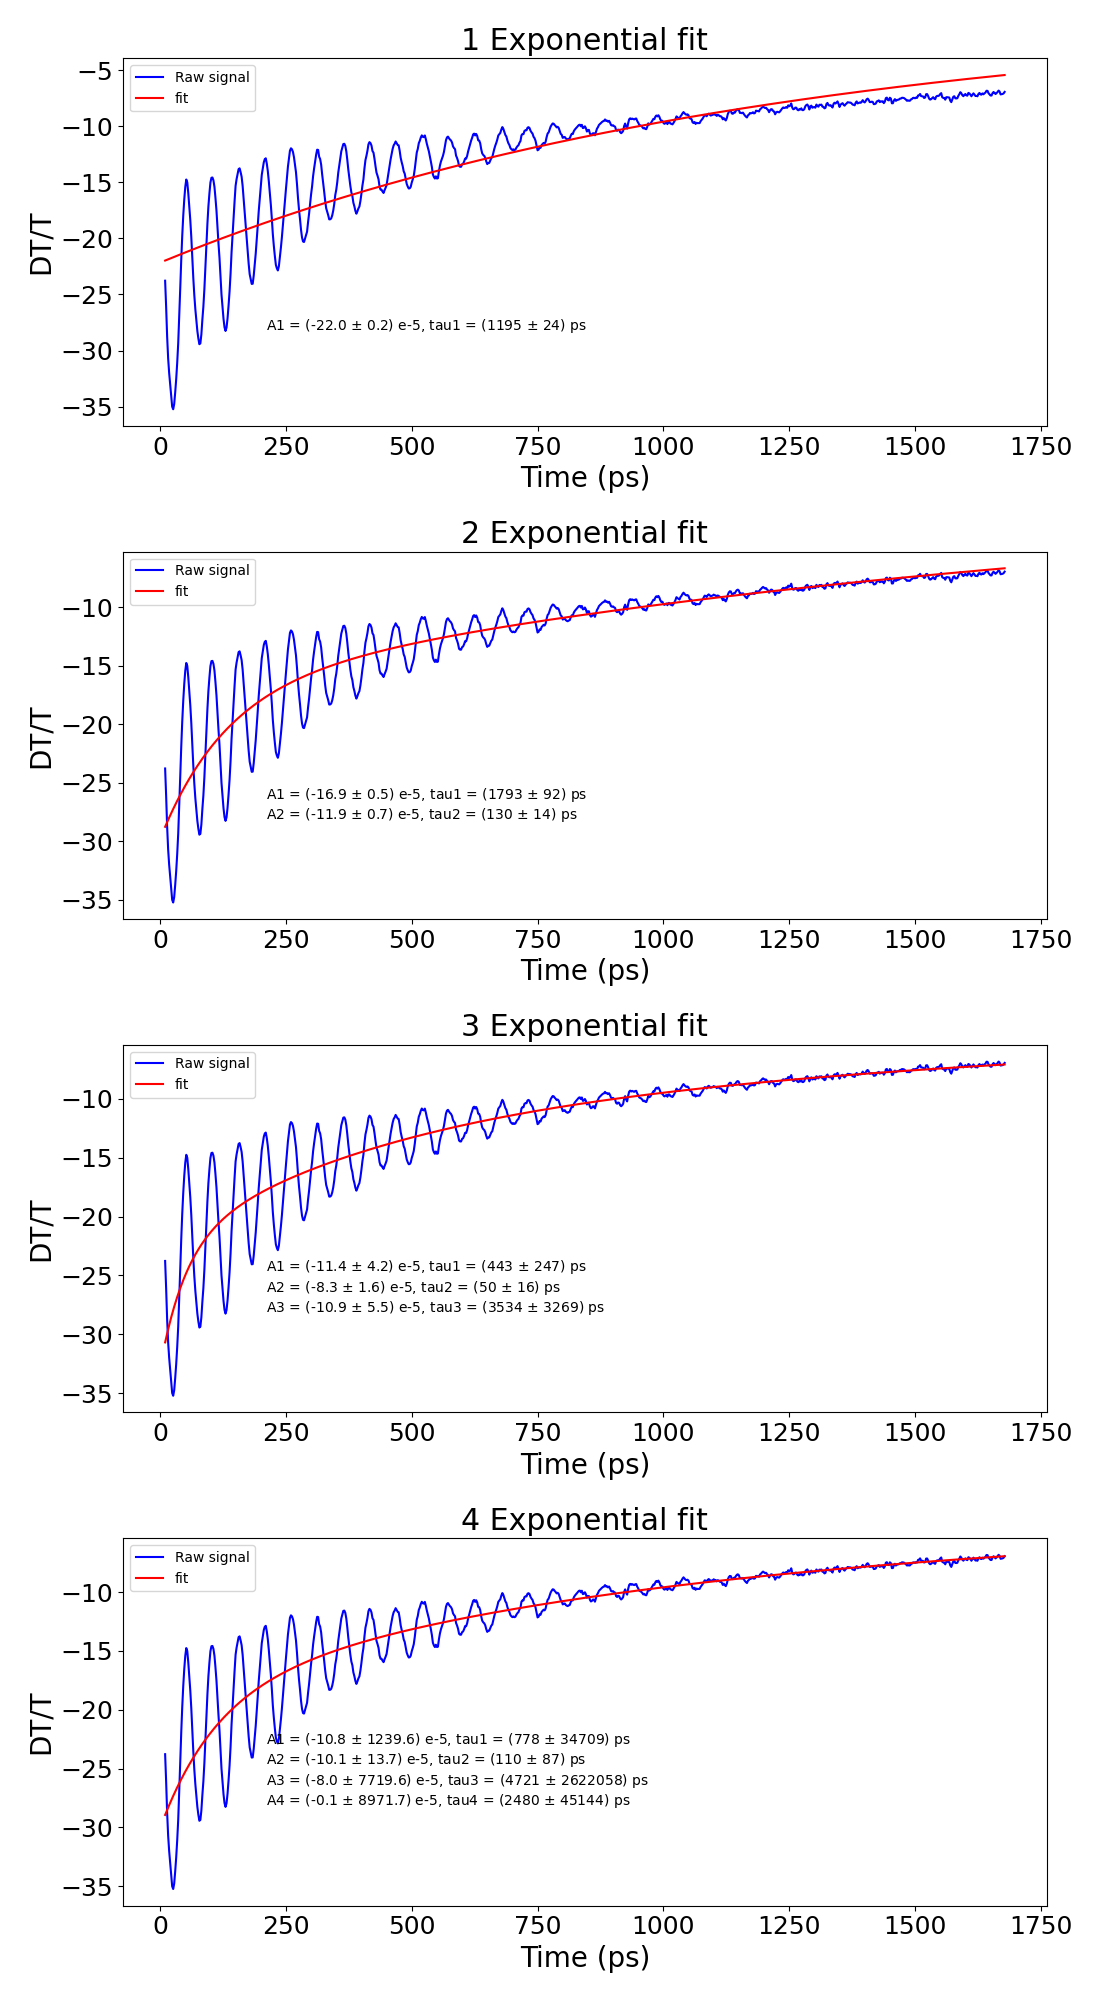

In [10]:
fig, ax = plt.subplots(nrows = 4,figsize = (11,20))

Plot_thermal_fit(Trace, ax[0], n_exp = 1)
Plot_thermal_fit(Trace, ax[1], n_exp = 2)
Plot_thermal_fit(Trace, ax[2], n_exp = 3)
Plot_thermal_fit(Trace, ax[3], n_exp = 4)
plt.tight_layout()
save_in_dir(fig, dir_save_treated_data, 'all_thermal_fits')



## Save Data

In [11]:
dir_to_save = Trace.dir_root + '\\' + Trace.dir_name + r'_treated'
filename_thermal_fit = filename + '_thermal_fitted'

save_PaP_dataset(Trace, dir_to_save, filename_thermal_fit)